In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42

In [4]:
calories = pd.read_csv("../data/calories.csv")
exercise = pd.read_csv("../data/exercise.csv")

df = exercise.merge(calories, on="User_ID", how="inner")
df = df.drop(columns=["User_ID"])
df["Gender"] = df["Gender"].str.strip().str.lower().map({"male": 1, "female": 0})

print(df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

(15000, 8)
Missing values: 0


,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,1,68,190.0,94.0,29.0,105.0,40.8,231.0
1,0,20,166.0,60.0,14.0,94.0,40.3,66.0
2,1,69,179.0,79.0,5.0,88.0,38.7,26.0
3,0,34,179.0,71.0,13.0,100.0,40.5,71.0
4,0,27,154.0,58.0,10.0,81.0,39.8,35.0


In [5]:
df["BMI"] = df["Weight"] / (df["Height"] / 100) ** 2
df["HR_x_Duration"] = df["Heart_Rate"] * df["Duration"]
df["Temp_x_Duration"] = df["Body_Temp"] * df["Duration"]

df.head()

,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,BMI,HR_x_Duration,Temp_x_Duration
0,1,68,190.0,94.0,29.0,105.0,40.8,231.0,26.038781,3045.0,1183.2
1,0,20,166.0,60.0,14.0,94.0,40.3,66.0,21.773842,1316.0,564.2
2,1,69,179.0,79.0,5.0,88.0,38.7,26.0,24.655910,440.0,193.5
3,0,34,179.0,71.0,13.0,100.0,40.5,71.0,22.159109,1300.0,526.5
4,0,27,154.0,58.0,10.0,81.0,39.8,35.0,24.456063,810.0,398.0


In [6]:
X = df.drop(columns=["Calories"])
y = df["Calories"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (12000, 10) | Test: (3000, 10)


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

results = []   # every model's scores will be stored here

def evaluate(name, model):
    """Fit the model, score it on train and test, store and print the result."""
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    row = {
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
    }
    results.append(row)

    print(f"{name}")
    print(f"  Train R2 = {row['Train R2']:.4f} | Test R2 = {row['Test R2']:.4f}")
    print(f"  Test MAE = {row['Test MAE']:.3f} | Test RMSE = {row['Test RMSE']:.3f}")
    return model

In [8]:
from sklearn.linear_model import LinearRegression

linear = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])

evaluate("Linear Regression", linear)

Linear Regression
  Train R2 = 0.9845 | Test R2 = 0.9845
  Test MAE = 5.819 | Test RMSE = 7.896


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Gender','Age','Height',...,'BMI','HR_x_Duration','Temp_x_Duration']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

poly2 = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", Ridge(alpha=1.0)),
])

poly3 = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("model", Ridge(alpha=10.0)),
])

evaluate("Polynomial (deg 2) + Ridge", poly2);
evaluate("Polynomial (deg 3) + Ridge", poly3);

Polynomial (deg 2) + Ridge
  Train R2 = 0.9986 | Test R2 = 0.9987
  Test MAE = 1.717 | Test RMSE = 2.329
Polynomial (deg 3) + Ridge
  Train R2 = 1.0000 | Test R2 = 1.0000
  Test MAE = 0.259 | Test RMSE = 0.302


In [10]:
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

svr = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVR(kernel="rbf", C=100, epsilon=1.0)),
])

rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)

evaluate("SVR (RBF)", svr);
evaluate("Random Forest", rf);

SVR (RBF)
  Train R2 = 0.9999 | Test R2 = 0.9999
  Test MAE = 0.436 | Test RMSE = 0.657
Random Forest
  Train R2 = 0.9997 | Test R2 = 0.9983
  Test MAE = 1.689 | Test RMSE = 2.645


In [11]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                   subsample=0.8, colsample_bytree=0.8,
                   random_state=SEED, n_jobs=-1)

lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                     random_state=SEED, verbose=-1, n_jobs=-1)

cat = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6,
                        random_seed=SEED, verbose=0)

evaluate("XGBoost", xgb);
evaluate("LightGBM", lgbm);
evaluate("CatBoost", cat);

XGBoost
  Train R2 = 0.9998 | Test R2 = 0.9996
  Test MAE = 0.957 | Test RMSE = 1.343
LightGBM
  Train R2 = 0.9998 | Test R2 = 0.9996
  Test MAE = 0.896 | Test RMSE = 1.343
CatBoost
  Train R2 = 0.9998 | Test R2 = 0.9997
  Test MAE = 0.778 | Test RMSE = 1.062


In [12]:
results_df = pd.DataFrame(results).sort_values("Test RMSE").reset_index(drop=True)
results_df.index = results_df.index + 1   # rank from 1
results_df.round(4)

,Model,Train R2,Test R2,Test MAE,Test RMSE
1,Polynomial (deg 3) + Ridge,1.0000,1.0000,0.2587,0.3016
2,SVR (RBF),0.9999,0.9999,0.4355,0.6570
3,CatBoost,0.9998,0.9997,0.7783,1.0617
4,LightGBM,0.9998,0.9996,0.8963,1.3427
5,XGBoost,0.9998,0.9996,0.9574,1.3429
6,Polynomial (deg 2) + Ridge,0.9986,0.9987,1.7166,2.3290
7,Random Forest,0.9997,0.9983,1.6887,2.6453
8,Linear Regression,0.9845,0.9845,5.8191,7.8965


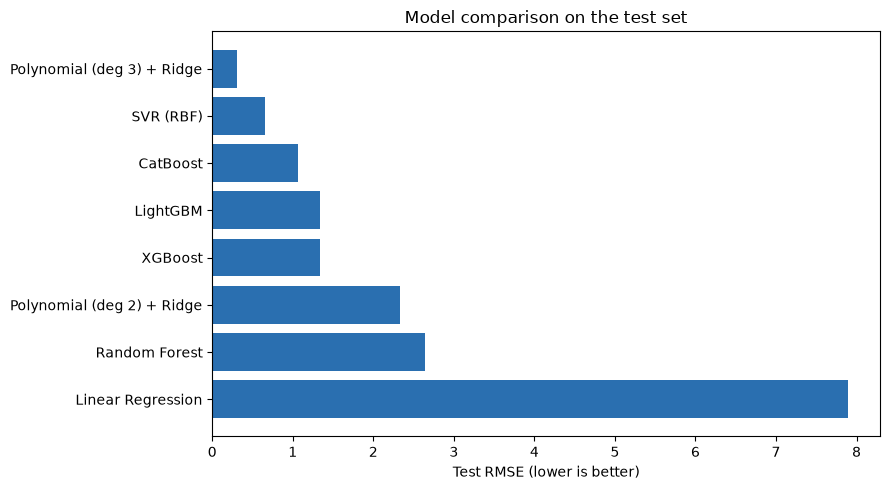

In [13]:
import os
os.makedirs("../figures", exist_ok=True)

order = results_df.sort_values("Test RMSE", ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(order["Model"], order["Test RMSE"], color="#2a6fb0")
plt.xlabel("Test RMSE (lower is better)")
plt.title("Model comparison on the test set")
plt.tight_layout()
plt.savefig("../figures/model_comparison.png", dpi=130)
plt.show()

In [14]:
from sklearn.model_selection import KFold, cross_validate

models = {
    "Linear Regression": linear,
    "Polynomial (deg 2) + Ridge": poly2,
    "Polynomial (deg 3) + Ridge": poly3,
    "SVR (RBF)": svr,
    "Random Forest": rf,
    "XGBoost": xgb,
    "LightGBM": lgbm,
    "CatBoost": cat,
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "CV R2": scores["test_r2"].mean(),
        "CV R2 std": scores["test_r2"].std(),
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV RMSE std": scores["test_rmse"].std(),
    })
    print("done:", name)

cv_df = pd.DataFrame(cv_rows).sort_values("CV RMSE").reset_index(drop=True)
cv_df.index = cv_df.index + 1
cv_df.round(4)

done: Linear Regression
done: Polynomial (deg 2) + Ridge
done: Polynomial (deg 3) + Ridge
done: SVR (RBF)
done: Random Forest
done: XGBoost
done: LightGBM
done: CatBoost


,Model,CV R2,CV R2 std,CV MAE,CV RMSE,CV RMSE std
1,Polynomial (deg 3) + Ridge,1.0000,0.0000,0.2602,0.3044,0.0044
2,SVR (RBF),0.9998,0.0000,0.4720,0.7764,0.0768
3,CatBoost,0.9996,0.0000,0.8209,1.1781,0.0788
4,XGBoost,0.9995,0.0001,0.9823,1.4297,0.0715
5,LightGBM,0.9994,0.0001,0.9445,1.4680,0.1363
6,Polynomial (deg 2) + Ridge,0.9986,0.0000,1.6913,2.3124,0.0308
7,Random Forest,0.9978,0.0001,1.8487,2.9236,0.0751
8,Linear Regression,0.9844,0.0003,5.7395,7.7586,0.0606


In [15]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# 1) Polynomial deg 3: tune the Ridge strength
poly3_search = GridSearchCV(
    poly3,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=3, scoring="neg_root_mean_squared_error",
)
poly3_search.fit(X_train, y_train)
print("Poly3 best:", poly3_search.best_params_, "| CV RMSE:", -poly3_search.best_score_)

# 2) SVR: tune C, epsilon, gamma
svr_search = RandomizedSearchCV(
    svr,
    param_distributions={
        "model__C": [10, 100, 300, 1000],
        "model__epsilon": [0.1, 0.5, 1.0],
        "model__gamma": [0.02, 0.05, 0.1, 0.2],
    },
    n_iter=12, cv=3, scoring="neg_root_mean_squared_error",
    random_state=SEED,
)
svr_search.fit(X_train, y_train)
print("SVR best:", svr_search.best_params_, "| CV RMSE:", -svr_search.best_score_)

# 3) CatBoost: tune depth, learning rate, iterations, regularization
cat_search = RandomizedSearchCV(
    CatBoostRegressor(random_seed=SEED, verbose=0),
    param_distributions={
        "depth": [4, 6, 8],
        "learning_rate": [0.03, 0.05, 0.1],
        "iterations": [600, 1000],
        "l2_leaf_reg": [1, 3, 5],
    },
    n_iter=8, cv=3, scoring="neg_root_mean_squared_error",
    random_state=SEED,
)
cat_search.fit(X_train, y_train)
print("CatBoost best:", cat_search.best_params_, "| CV RMSE:", -cat_search.best_score_)

Poly3 best: {'model__alpha': 1} | CV RMSE: 0.2932991843210795
SVR best: {'model__gamma': 0.02, 'model__epsilon': 0.5, 'model__C': 1000} | CV RMSE: 0.3277975453064441
CatBoost best: {'learning_rate': 0.05, 'l2_leaf_reg': 3, 'iterations': 1000, 'depth': 8} | CV RMSE: 0.9905007444209918


In [16]:
evaluate("Polynomial (deg 3) + Ridge [tuned]", poly3_search.best_estimator_);
evaluate("SVR (RBF) [tuned]", svr_search.best_estimator_);
evaluate("CatBoost [tuned]", cat_search.best_estimator_);

Polynomial (deg 3) + Ridge [tuned]
  Train R2 = 1.0000 | Test R2 = 1.0000
  Test MAE = 0.255 | Test RMSE = 0.294
SVR (RBF) [tuned]
  Train R2 = 1.0000 | Test R2 = 1.0000
  Test MAE = 0.261 | Test RMSE = 0.308
CatBoost [tuned]
  Train R2 = 0.9999 | Test R2 = 0.9998
  Test MAE = 0.524 | Test RMSE = 0.785


In [17]:
final_df = pd.DataFrame(results).sort_values("Test RMSE").reset_index(drop=True)
final_df.index = final_df.index + 1
final_df.round(4)

,Model,Train R2,Test R2,Test MAE,Test RMSE
1,Polynomial (deg 3) + Ridge [tuned],1.0000,1.0000,0.2549,0.2944
2,Polynomial (deg 3) + Ridge,1.0000,1.0000,0.2587,0.3016
3,SVR (RBF) [tuned],1.0000,1.0000,0.2613,0.3082
4,SVR (RBF),0.9999,0.9999,0.4355,0.6570
5,CatBoost [tuned],0.9999,0.9998,0.5241,0.7848
6,CatBoost,0.9998,0.9997,0.7783,1.0617
7,LightGBM,0.9998,0.9996,0.8963,1.3427
8,XGBoost,0.9998,0.9996,0.9574,1.3429
9,Polynomial (deg 2) + Ridge,0.9986,0.9987,1.7166,2.3290
10,Random Forest,0.9997,0.9983,1.6887,2.6453


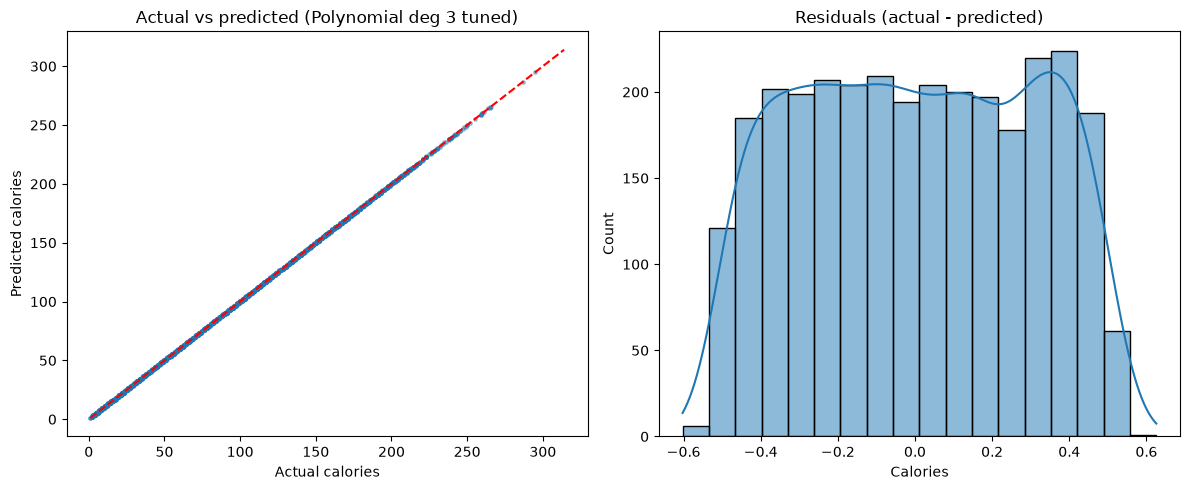

In [19]:
poly3_best = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("model", Ridge(alpha=1)),
])
poly3_best.fit(X_train, y_train)

best = poly3_best
pred = best.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, pred, s=6, alpha=0.4)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set_xlabel("Actual calories")
axes[0].set_ylabel("Predicted calories")
axes[0].set_title("Actual vs predicted (Polynomial deg 3 tuned)")

sns.histplot(y_test - pred, kde=True, ax=axes[1])
axes[1].set_title("Residuals (actual - predicted)")

plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/best_model_diagnostics.png", dpi=130)
plt.show()